In [68]:
%load_ext pyspecdata.ipy
from pyspecdata import (
    figlist_var,
    find_file,
    search_filename,
    concat,
    lmfitdata,
)
from matplotlib.pyplot import text, gca, xlabel, ylabel
import numpy as np
import pandas as pd
import re
import os
import sympy as sp
import dateutil
from pathlib import Path

The pyspecdata.ipy extension is already loaded. To reload it, use:
  %reload_ext pyspecdata.ipy


In [69]:
df = pd.read_excel("temperature_log_clean_250402_20mM.xlsx")
df.columns

Index(['Filename', 'Time', 'Temperature'], dtype='object')

In [70]:
unique_filenames = df['Filename'].unique()
df['Time'] = pd.to_datetime(df['Time'])
start_time = {
    fname: df[df["Filename"] == fname]["Time"].min()
    for fname in unique_filenames
}

In [71]:
temperature_dict = {
    fname: df[df["Filename"] == fname]["Temperature"].tolist()
    for fname in unique_filenames
}

In [72]:
for fname in unique_filenames:
    print(f"Processing {fname}, Start time: {start_time[fname]}\n temp: {temperature_dict[fname]}")  

Processing 250402_20mM_TSO4_C8_W20_ThickID_333K.DSC, Start time: 2025-04-02 17:22:30
 temp: [333.0, 333.0]
Processing 250402_20mM_TSO4_C8_W20_ThickID_330K.DSC, Start time: 2025-04-02 17:33:10
 temp: [330.0, 330.0]
Processing 250402_20mM_TSO4_C8_W20_ThickID_325K.DSC, Start time: 2025-04-02 17:48:00
 temp: [325.0, 325.0]
Processing 250402_20mM_TSO4_C8_W20_ThickID_320K.DSC, Start time: 2025-04-02 18:00:40
 temp: [320.0, 320.0]
Processing 250402_20mM_TSO4_C8_W20_ThickID_315K.DSC, Start time: 2025-04-02 18:13:18
 temp: [315.0, 315.0]
Processing 250402_20mM_TSO4_C8_W20_ThickID_310K.DSC, Start time: 2025-04-02 18:30:14
 temp: [310.0, 310.0]
Processing 250402_20mM_TSO4_C8_W20_ThickID_305K.DSC, Start time: 2025-04-02 18:46:03
 temp: [305.0, 305.0]
Processing 250402_20mM_TSO4_C8_W20_ThickID_300K.DSC, Start time: 2025-04-02 19:01:02.390000
 temp: [300.0, 301.34, 299.13, 299.88, 300.16, 299.97, 300.0]
Processing 250402_20mM_TSO4_C8_W20_ThickID_295K.DSC, Start time: 2025-04-02 19:22:50
 temp: [295.

In [73]:
tempsearch_re = re.compile(r"ThickID_(.*)\.")
all_files_sorted = sorted(unique_filenames, key=lambda x: tempsearch_re.search(x).groups()[0])

In [74]:
all_files = {}
for fname in unique_filenames:
    all_files[fname] = find_file(fname, exp_type="francklab_esr/romana")
    all_files[fname] = all_files[fname].chunk_auto("harmonic", "harmonic")["harmonic", 0]["phase", 0]

In [75]:
print(all_files_sorted)

['250402_20mM_TSO4_C8_W20_ThickID_245K_222K.DSC', '250402_20mM_TSO4_C8_W20_ThickID_275K_245K.DSC', '250402_20mM_TSO4_C8_W20_ThickID_280K.DSC', '250402_20mM_TSO4_C8_W20_ThickID_285K.DSC', '250402_20mM_TSO4_C8_W20_ThickID_290K.DSC', '250402_20mM_TSO4_C8_W20_ThickID_295K.DSC', '250402_20mM_TSO4_C8_W20_ThickID_300K.DSC', '250402_20mM_TSO4_C8_W20_ThickID_305K.DSC', '250402_20mM_TSO4_C8_W20_ThickID_310K.DSC', '250402_20mM_TSO4_C8_W20_ThickID_315K.DSC', '250402_20mM_TSO4_C8_W20_ThickID_320K.DSC', '250402_20mM_TSO4_C8_W20_ThickID_325K.DSC', '250402_20mM_TSO4_C8_W20_ThickID_330K.DSC', '250402_20mM_TSO4_C8_W20_ThickID_333K.DSC', '250402_20mM_TSO4_C8_W20_ThickID_Reheat_222K_300K.DSC']


1: normalization |||min
2: Temperature
3: all spectra!



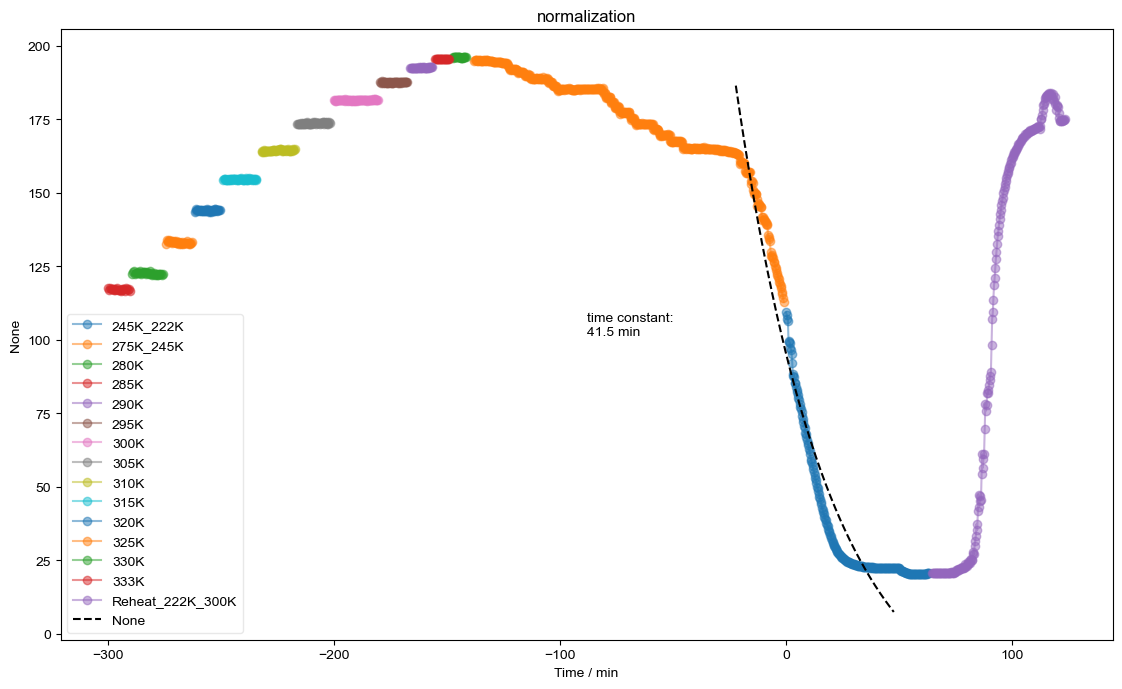

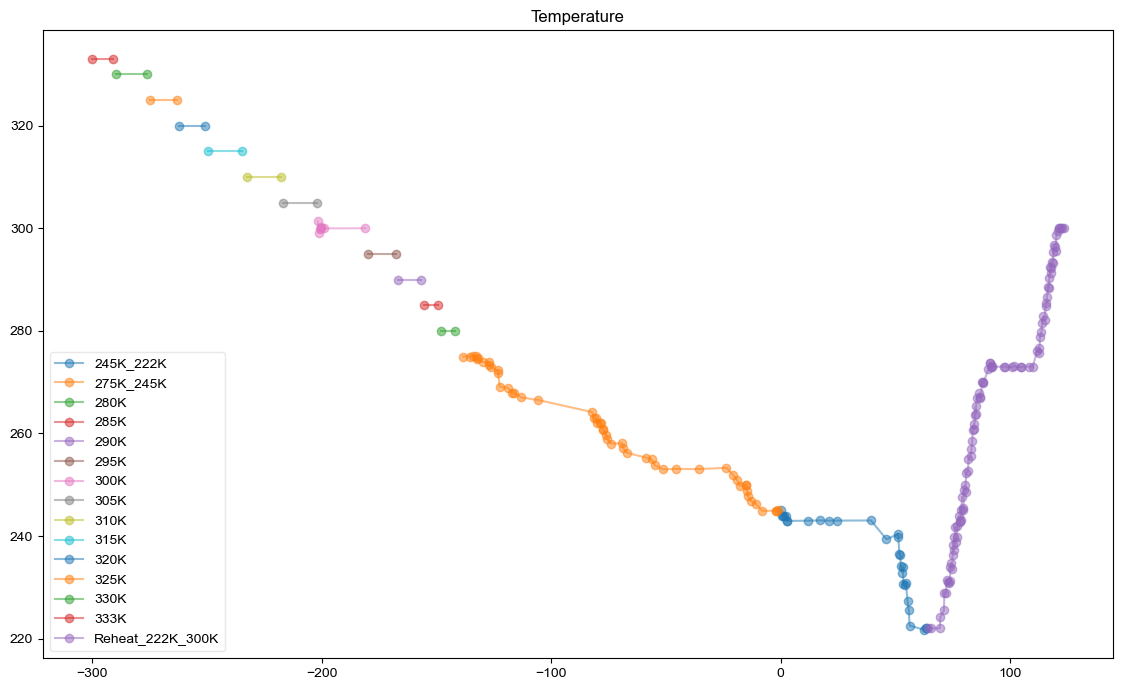

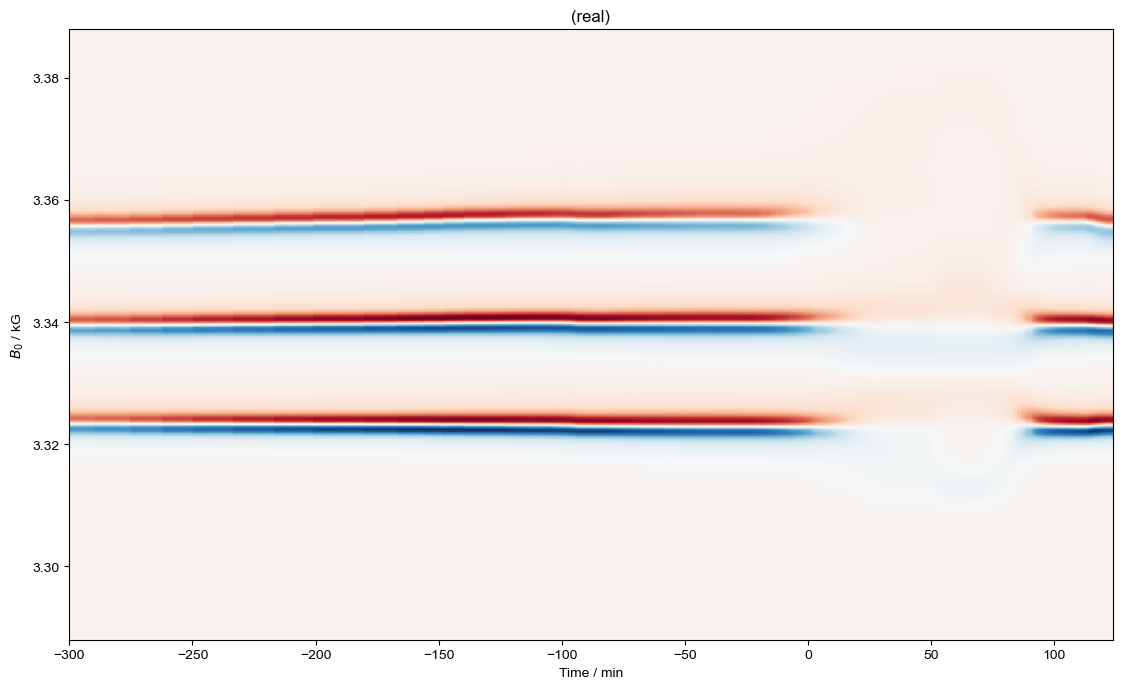

In [76]:
all_spectra = []
all_norm = []

n_max, n_min, R, t = sp.symbols("n_max n_min R Time", positive=True)
def hhmmss_to_seconds(time_str, date_str, ref_datetime):
    full_time = dateutil.parser.parse(f"{date_str} {time_str}")
    return (full_time - ref_time).total_seconds()

with figlist_var() as fl:
    for j, thisfile in enumerate(all_files_sorted):
        T_string = tempsearch_re.search(thisfile).groups()[0]
        d = all_files[thisfile]
        
        # {{{ to remove empty zeros when we ESR stopped early
        mask = abs(d).sum("$B_0$") > 0
        d = d["Time", mask.data]
        # }}}

        # Get earliest start time from Excel 
        if j == 0:
            ref_time = start_time[thisfile]  
        
        # Time axis: align to reference 
        d["Time"] -= d["Time"][-1]
        d["Time"] += hhmmss_to_seconds(
            d.get_prop("TIME"), d.get_prop("DATE"), ref_time
        )
        d["Time"] /= 60
        d.set_units("Time", "min")

        # Normalize
        normalization = d.C.run(np.amax, "$B_0$")
        normalization -= d.C.run(np.amin, "$B_0$")
        fl.next("normalization")
        fl.plot(normalization, "o-", label=T_string)

        # store
        all_norm.append(normalization)
        all_spectra.append(d)

        # Plot temperature vs. time from Excel
        excel_subset = df[df["Filename"] == thisfile].copy()
        excel_subset = excel_subset.sort_values(by="Time")
        temp_time = (excel_subset["Time"] - ref_time).dt.total_seconds() / 60  # in minutes
        temp_vals = excel_subset["Temperature"]
        fl.next("Temperature")
        fl.plot(temp_time, temp_vals, "o-", label=f"{T_string}")

    # concatanate all data
    all_spectra = concat(all_spectra, dimname="Time").sort("Time")
    all_norm = concat(all_norm, dimname="Time").sort("Time")

    # plot
    fl.next("all spectra!")
    all_spectra.pcolor(cmap="RdBu")

    # # Subplot for Normalization & Temperature vs. Time
    # ## concatenate
    # all_temp_times = np.concatenate(all_temp_times) #, dimname="Time").sort("Time")
    # all_temp_vals = np.concatenate(all_temp_vals) #, dimname="Time").sort("Time")
    # ## plot
    # fl.next("Normalization & Temperature vs. Time")
    # fig, (ax1, ax2) = subplots(2,1, sharex = True)
    # fl.plot(all_norm, "o-", ax= ax1, label=T_string)
    # # fl.plot(all_temp_times, all_temp_vals, "o-", ax=ax2, label=f"{T_string}K") 
    # for j, (t_vals, temp_vals) in enumerate(zip(all_temp_times, all_temp_vals)):
    #     fl.plot(t_vals, temp_vals, "o-", ax=ax2, alpha=0.7)
    
    # {{{ here we use the normalization curve to fit a time constant for
    #     the shedding process
    fl.next("normalization")
    all_norm = lmfitdata(all_norm["Time":(-22.3, 48)])
    t_start = all_norm["Time"][0]
    all_norm["Time"] -= t_start  # make fitting easier
    all_norm.functional_form = n_min + sp.exp(-R * t) * (n_max - n_min)
    all_norm.set_guess(
        n_max=all_norm["Time", 0].item(),
        n_min=all_norm["Time", -1].item(),
        R=0.03,  # rate per minute
    )
    do_fit = True  # set to False to check the guess
    if do_fit:
        all_norm.fit()
    else:
        all_norm.settoguess()  # do this first to see if guess is reasonable
    fit_curve = all_norm.eval()
    fit_curve["Time"] += t_start
    fl.plot(fit_curve, color="k", ls="--", alpha=1.0)
    text(
        0.5,
        0.5,
        f"time constant:\n{1/all_norm.output('R'):#0.3g} min",
        transform=gca().transAxes,
    )
    # }}}

1: Normalization & Temperature vs Time |||min



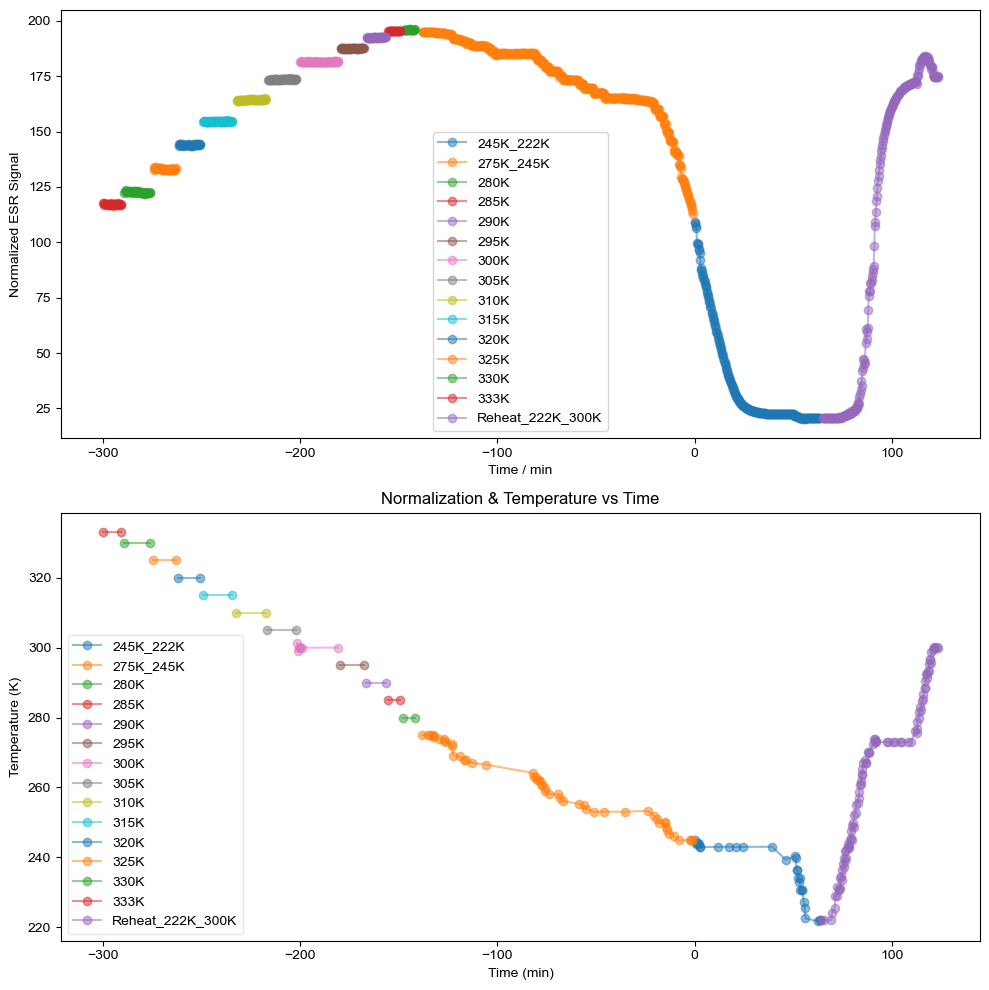

In [77]:
all_spectra = []
all_norm = []

with figlist_var() as fl:
    fig, (ax1, ax2) = subplots(2,1, sharex = True, figsize=(10,10))
    for j, thisfile in enumerate(all_files_sorted):
        T_string = tempsearch_re.search(thisfile).groups()[0]
        d = all_files[thisfile]
        
        # {{{ to remove empty zeros when we ESR stopped early
        mask = abs(d).sum("$B_0$") > 0
        d = d["Time", mask.data]
        # }}}

        # Get earliest start time from Excel 
        if j == 0:
            ref_time = start_time[thisfile]  
        
        # Time axis: align to reference 
        d["Time"] -= d["Time"][-1]
        d["Time"] += hhmmss_to_seconds(
            d.get_prop("TIME"), d.get_prop("DATE"), ref_time
        )
        d["Time"] /= 60
        d.set_units("Time", "min")

        # Normalize
        normalization = d.C.run(np.amax, "$B_0$")
        normalization -= d.C.run(np.amin, "$B_0$")

        # store
        all_norm.append(normalization)
        # all_spectra.append(d)

        # temperature vs. time from Excel
        excel_subset = df[df["Filename"] == thisfile].copy()
        excel_subset = excel_subset.sort_values(by="Time")
        temp_time = (excel_subset["Time"] - ref_time).dt.total_seconds() / 60  # in minutes
        temp_vals = excel_subset["Temperature"]

        # subplot
        fl.next("Normalization & Temperature vs Time")
        fl.plot(normalization, "o-", ax=ax1, label=f"{T_string}")        
        fl.plot(temp_time, temp_vals, "o-", ax=ax2, label=f"{T_string}")
        ax1.legend()
        ax2.legend()
        ax1.set_ylabel("Normalized ESR Signal")
        ax2.set_ylabel("Temperature (K)")
        ax2.set_xlabel("Time (min)")
        ax1.tick_params(labelbottom=True)

In [ ]:
all_spectra = []
all_norm = []

n_max, n_min, R, t = sp.symbols("n_max n_min R Time", positive=True)
def hhmmss_to_seconds(time_str, date_str, ref_datetime):
    full_time = dateutil.parser.parse(f"{date_str} {time_str}")
    return (full_time - ref_time).total_seconds()

with figlist_var() as fl:
    for j, thisfile in enumerate(all_files_sorted):
        T_string = tempsearch_re.search(thisfile).groups()[0]
        d = all_files[thisfile]
        
        # {{{ to remove empty zeros when we ESR stopped early
        mask = abs(d).sum("$B_0$") > 0
        d = d["Time", mask.data]
        # }}}

        # # excel time extract
        # excel_subset = df[df["Filename"] == thisfile].copy
        # excel_subset = excel_subset.sort_values("Time")
        
        # # Get earliest start time from Excel 
        # if j == 0:
        #     ref_time = excel_subset["Time"].iloc[0]  
        # Interpolate to match ESR length
        # excel_time = (excel_subset["Time"] - ref_time).dt.total_seconds() / 60  # in minutes
        # d["Time"] = np.linspace(excel_time.iloc[0], excel_time.iloc[-1], len(d["Time"]))
        # d.set_units("Time", "min")

        
        # # Previous Time axis: align to reference 
        # d["Time"] -= d["Time"][-1]
        # d["Time"] += hhmmss_to_seconds(
        #     d.get_prop("TIME"), d.get_prop("DATE"), ref_time
        # )
        # d["Time"] /= 60
        # d.set_units("Time", "min")

        # Normalize
        normalization = d.C.run(np.amax, "$B_0$")
        normalization -= d.C.run(np.amin, "$B_0$")
        fl.next("normalization")
        fl.plot(normalization, "o-", label=T_string)

        # store
        all_norm.append(normalization)
        all_spectra.append(d)

        # Plot temperature vs. time from Excel
        excel_subset = df[df["Filename"] == thisfile].copy()
        excel_subset = excel_subset.sort_values(by="Time")
        temp_time = (excel_subset["Time"] - ref_time).dt.total_seconds() / 60  # in minutes
        temp_vals = excel_subset["Temperature"]
        fl.next("Temperature")
        fl.plot(temp_time, temp_vals, "o-", label=f"{T_string}")

    # concatanate all data
    all_spectra = concat(all_spectra, dimname="Time").sort("Time")
    all_norm = concat(all_norm, dimname="Time").sort("Time")

    # plot
    fl.next("all spectra!")
    all_spectra.pcolor(cmap="RdBu")

    # # Subplot for Normalization & Temperature vs. Time
    # ## concatenate
    # all_temp_times = np.concatenate(all_temp_times) #, dimname="Time").sort("Time")
    # all_temp_vals = np.concatenate(all_temp_vals) #, dimname="Time").sort("Time")
    # ## plot
    # fl.next("Normalization & Temperature vs. Time")
    # fig, (ax1, ax2) = subplots(2,1, sharex = True)
    # fl.plot(all_norm, "o-", ax= ax1, label=T_string)
    # # fl.plot(all_temp_times, all_temp_vals, "o-", ax=ax2, label=f"{T_string}K") 
    # for j, (t_vals, temp_vals) in enumerate(zip(all_temp_times, all_temp_vals)):
    #     fl.plot(t_vals, temp_vals, "o-", ax=ax2, alpha=0.7)
    
    # {{{ here we use the normalization curve to fit a time constant for
    #     the shedding process
    fl.next("normalization")
    all_norm = lmfitdata(all_norm["Time":(-22.3, 48)])
    t_start = all_norm["Time"][0]
    all_norm["Time"] -= t_start  # make fitting easier
    all_norm.functional_form = n_min + sp.exp(-R * t) * (n_max - n_min)
    all_norm.set_guess(
        n_max=all_norm["Time", 0].item(),
        n_min=all_norm["Time", -1].item(),
        R=0.03,  # rate per minute
    )
    do_fit = True  # set to False to check the guess
    if do_fit:
        all_norm.fit()
    else:
        all_norm.settoguess()  # do this first to see if guess is reasonable
    fit_curve = all_norm.eval()
    fit_curve["Time"] += t_start
    fl.plot(fit_curve, color="k", ls="--", alpha=1.0)
    text(
        0.5,
        0.5,
        f"time constant:\n{1/all_norm.output('R'):#0.3g} min",
        transform=gca().transAxes,
    )
    # }}}

In [7]:
all_files = {}
for k, fname in [
    # Sample name: 20 mM TEMPO-SO4 in isooctane 250402
    ("d_333K", "250402_20mM_TSO4_C8_W20_ThickID_333K.DSC"),
    ("d_330K", "250402_20mM_TSO4_C8_W20_ThickID_330K.DSC"),
    ("d_325K", "250402_20mM_TSO4_C8_W20_ThickID_325K.DSC"),
    ("d_320K", "250402_20mM_TSO4_C8_W20_ThickID_320K.DSC"),
    ("d_315K", "250402_20mM_TSO4_C8_W20_ThickID_315K.DSC"),
    ("d_310K", "250402_20mM_TSO4_C8_W20_ThickID_310K.DSC"),
    ("d_305K", "250402_20mM_TSO4_C8_W20_ThickID_305K.DSC"),
    ("d_300K", "250402_20mM_TSO4_C8_W20_ThickID_300K.DSC"),
    ("d_295K", "250402_20mM_TSO4_C8_W20_ThickID_295K.DSC"),
    ("d_290K", "250402_20mM_TSO4_C8_W20_ThickID_290K.DSC"),
    ("d_285K", "250402_20mM_TSO4_C8_W20_ThickID_285K.DSC"),
    ("d_280K", "250402_20mM_TSO4_C8_W20_ThickID_280K.DSC"),
    ("d_275_245K", "250402_20mM_TSO4_C8_W20_ThickID_275K_245K.DSC"),
    ("d_245_222K", "250402_20mM_TSO4_C8_W20_ThickID_245K_222K.DSC"),
    ("d_reheat_222_300K", "250402_20mM_TSO4_C8_W20_ThickID_Reheat_222K_300K.DSC"),
]:
    all_files[k] = find_file(fname, exp_type="francklab_esr/romana")
    all_files[k] = all_files[k].chunk_auto("harmonic", "harmonic")["harmonic", 0]["phase", 0]